# 1. Objective

Implement finite difference PDE solver for Black Scholes equation via three different methods

- Explicit

- Implicit 

- Crank-Nicolson

# 2. Preliminary

## 2.1 Finite difference

Split time period $[0,T]$ into $N$ equally divided intervals via $N+1$ segment points

$$
0,\,\Delta t,\,2\Delta t,\,\cdots,\, N\Delta t,\qquad \Delta t=\frac{T}{N}.  
$$

Suppose $S_{max}$ is high enough such that when the stock price reaches this price, the put option is deep out of the money. We split 
$S_{max}$ into $M$ intervals with the same size $\Delta S=S_{max}/M$ and derive corresponding points

$$
0,\,\Delta S,\,2\Delta S,\, \cdots,\, M\Delta S,\qquad \Delta S=\frac{S_{max}}{M}.
$$

We now have the time-space grid for put option $p_{i,j}=p(i\Delta t,j\Delta S)$. Impose the boundary conditions 

$$
p_{N,j}=(K-j\Delta S)^+,
$$

$$
p_{i,0}=Ke^{-r(T-i\Delta t)},\qquad p_{i,M}=0. 
$$

Denote the finite difference operator $L_h$ as 

$$
L_h p_{i,j}=\alpha_j p_{i,j-1}+\beta_j p_{i,j}+\gamma_j p_{i,j+1},
$$

here the coefficients are 

$$
\begin{aligned}
&\alpha_j=\frac{1}{2}\sigma^2j^2-\frac{1}{2}(r-q)j,\\
&\beta_j=-\sigma^2j^2-r,\\
&\gamma_j=\frac{1}{2}\sigma^2j^2+\frac{1}{2}(r-q)j. 
\end{aligned}
$$

## 2.2 Explicit finite difference solver

We evaluate all terms in the discrete spatial operator $L_h$, including the discount term, at the known time level $t_{i+1}$. This leads to an explicit backward-time scheme

$$
\frac{p_{i+1,j}-p_{i,j}}{\Delta t}
+L_hp_{i+1,j}=0. 
$$

Hence we get the explict PDE solver 

$$
p_{i,j}=a_j p_{i+1,j-1}+b_j p_{i+1,j}+c_j p_{i+1,j+1},
$$

where 

$$
\begin{aligned}
&a_j=\frac{1}{2}\sigma^2j^2\Delta t-\frac{1}{2}(r-q)j\Delta t,\\
&b_j=1-\sigma^2j^2\Delta t-r\Delta t,\\
&c_j=\frac{1}{2}\sigma^2 j^2\Delta t+\frac{1}{2}(r-q)j\Delta t.  
\end{aligned}
$$

## 2.3 Implicit finite difference solver

$$
p_{i,j}=p_{i+1,j}+\Delta t L_h p_{i,j}
$$

derives the implicit PDE solver

$$
\begin{pmatrix}
b_1&c_1&0&\cdots&0\\
a_2&b_2&c_2&\cdots&0\\
0&a_3&b_3&\ddots&\vdots\\
\vdots&\ddots&\ddots&\ddots&c_{M-2}\\
0&\cdots&0&a_{M-1}&b_{M-1}
\end{pmatrix}
\begin{pmatrix}
p_{i,1}\\
p_{i,2}\\
\vdots\\
p_{i,M-2}\\
p_{i,M-1}
\end{pmatrix}
=
\begin{pmatrix}
p_{i+1,1}-a_1p_{i,0}\\
p_{i+1,2}\\
\vdots\\
p_{i+1,M-2}\\
p_{i+1,M-1}-c_{M-1}p_{i,M}
\end{pmatrix},
$$

where 

$$
\begin{aligned}
a_j&=\frac{\Delta t}{2}((r-q)j-\sigma^2j^2),\\
b_j&=1+\Delta t(\sigma^2j^2+r),\\
c_j&=-\frac{\Delta t}{2}((r-q)j+\sigma^2j^2).
\end{aligned}
$$

## 2.4 Crank-Nicolson

$$
p_{i,j}=p_{i+1,j}+\frac{\Delta t}{2}(L_h p_{i,j}+L_h p_{i+1,j})
$$

and we can have 

$$
\begin{pmatrix}
b_1^*&c_1^*&&\\
a_2^*&b_2^*&c_2^*&\\
&\ddots&\ddots&\ddots\\
&&a_{M-1}^*&b_{M-1}^*
\end{pmatrix}
\begin{pmatrix}
p_{i,1}\\
p_{i,2}\\
\vdots\\
p_{i,M-1}
\end{pmatrix}
=
\begin{pmatrix}
\widetilde b_1^*&-c_1^*&&\\
-a_2^*&\widetilde b_2^*&-c_2^*&\\
&\ddots&\ddots&\ddots\\
&&-a_{M-1}^*&\widetilde b_{M-1}^*
\end{pmatrix}
\begin{pmatrix}
p_{i+1,1}\\
p_{i+1,2}\\
\vdots\\
p_{i+1,M-1}
\end{pmatrix}
+
\begin{pmatrix}
-a_1^*p_{i+1,0}-a_1^*p_{i,0}\\
0\\
\vdots\\
0\\
-c_{M-1}^*p_{i+1,M}-c_{M-1}^*p_{i,M}
\end{pmatrix}.
$$

The coefficients are the following 

$$
\begin{aligned}
a_j^*&=\frac{\Delta t}{4}((r-q)j-\sigma^2j^2),\\
b_j^*&=1+\frac{\Delta t}{2}(\sigma^2j^2+r),\\
c_j^*&=-\frac{\Delta t}{4}((r-q)j+\sigma^2j^2),\\
\widetilde b_j^*&
=1-\frac{\Delta t}{2}(\sigma^2j^2+r).
\end{aligned}
$$

# 3. Experiment Design

Consider a $5$-month European put option on a dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, the continuous dividend yield is $0.3\%$ and the volatility is $40\%$ per annum. This means that $S_0=50,K=50,r=0.1,q=0.003,\sigma=0.4,T=5/12$.

# 4. Numerical Implementation

In [7]:
import sys
from pathlib import Path

PROJECT_ROOT=Path.cwd().parent
SRC_DIR=PROJECT_ROOT/'src'

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0,str(SRC_DIR))

print(str(SRC_DIR) in sys.path)

True


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The exact put price form BS formula is: 4.1001.

For N in [1000, 2000, 4000, 8000, 16000, 32000], 
the explicit solver gives put price: [4.08578416 4.08545859 4.08529581 4.08521442 4.08517373 4.08515338], 
the implicit solver gives put price: [4.08448199 4.08480751 4.08497027 4.08505165 4.08509234 4.08511269], 
the Crank Nicolson solver gives put price: [4.0851332  4.08513308 4.08513305 4.08513304 4.08513304 4.08513304].

order estimate for explicit: [1.00006653 1.00003329 1.00001663 1.00000836].
order estimate for implicit: [0.99993332 0.99996669 0.99998331 0.99999133].
order estimate for Crank-Nicolson: [1.99999314 2.00003013 2.00197842 1.99493174].


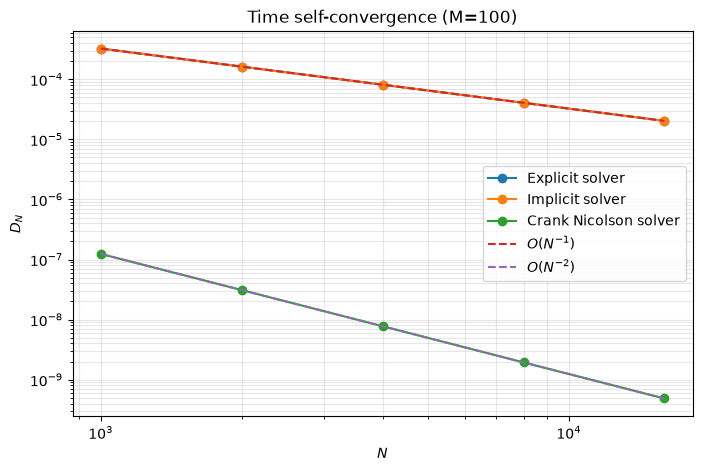

In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import black_scholes as bs
import monte_carlo as mc
import pde_solver as fd 


S0=50;K=50;T=5/12;r=0.1;q=0.003;sigma=0.4

# Time Convergence
Smax=200
M=100
N_interval=[1000,2000,4000,8000,16000,32000]

# exact put option price form bs formula 
put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')
print(f'The exact put price form BS formula is: {put_bs:.4f}.')

# finite difference PDE solver
put_explicit=[]
put_implicit=[]
put_cn=[]
for N in N_interval:
    put_explicit.append(fd.bs_put_explicit(S0,K,T,r,q,sigma,M,N,Smax))
    put_implicit.append(fd.bs_put_implicit(S0,K,T,r,q,sigma,M,N,Smax))
    put_cn.append(fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma,M,N,Smax))

put_explicit=np.array(put_explicit)
put_implicit=np.array(put_implicit)
put_cn=np.array(put_cn)
print()
print(f'For N in {N_interval}, \nthe explicit solver gives put price: {np.round(put_explicit,8)}, \nthe implicit solver gives put price: {np.round(put_implicit,8)}, \nthe Crank Nicolson solver gives put price: {np.round(put_cn,8)}.')

# D_N=|P_{M,2N}(0,S0)-P_{M,N}(0,S0)|
D_explicit=np.abs(put_explicit[:-1]-put_explicit[1:])
D_implicit=np.abs(put_implicit[:-1]-put_implicit[1:])
D_cn=np.abs(put_cn[:-1]-put_cn[1:])

# Order estimation
## p=log_2(D_{N}/D_{2N})
p_explicit=np.log2(D_explicit[:-1]/D_explicit[1:])
p_implicit=np.log2(D_implicit[:-1]/D_implicit[1:])
p_cn=np.log2(D_cn[:-1]/D_cn[1:])
print()
print(f'order estimate for explicit: {p_explicit}.')
print(f'order estimate for implicit: {p_implicit}.')
print(f'order estimate for Crank-Nicolson: {p_cn}.')

# Plot 
N_plot=np.array(N_interval[:-1])
ref_first=D_explicit[0]*(N_plot/N_plot[0])**(-1)
ref_second=D_cn[0]*(N_plot/N_plot[0])**(-2)

fig,ax=plt.subplots(figsize=(8,5))
plt.loglog(N_plot,D_explicit,'o-',label=r'Explicit solver')
plt.loglog(N_plot,D_implicit,'o-',label=r'Implicit solver')
plt.loglog(N_plot,D_cn,'o-',label=r'Crank Nicolson solver')

plt.loglog(N_plot,ref_first,'--',label=r'$O(N^{-1})$')
plt.loglog(N_plot,ref_second,'--',label=r'$O(N^{-2})$')

plt.xlabel(r'$N$')
plt.ylabel(r'$D_N$')
plt.title(r'Time self-convergence (M=100)')
plt.grid(True,which='both',alpha=0.3)
plt.legend()
plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'02_pde_temporal_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

The exact put price form BS formula is: 4.1001.

For M in [40, 80, 160, 320, 640], 
Crank Nicolson gives put price: [4.00402727 4.07663774 4.09428843 4.09867273 4.09976707].

Order estimates for Crank Nicolson are: [2.03231284 2.00744406 2.00182792 2.00045525].


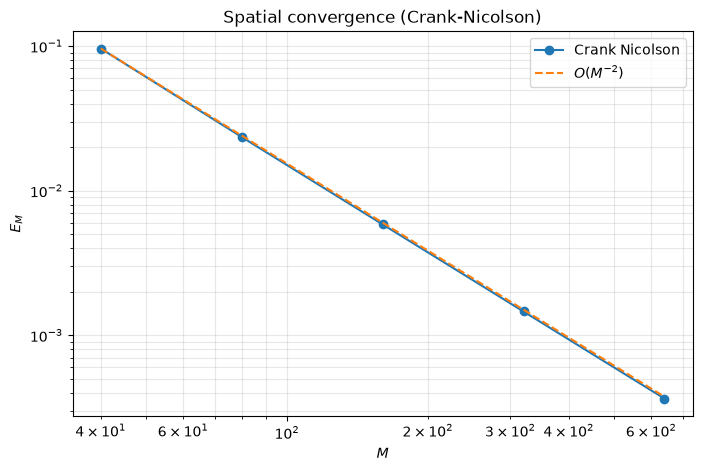

In [9]:
# Spatial Convergence
N=42000
M_interval=[40,80,160,320,640]

# exact put option price form bs formula 
put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')
print(f'The exact put price form BS formula is: {put_bs:.4f}.')

# Crank Nicolson
put_cn=[]
for M in M_interval:
    put_cn.append(fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma,M,N,Smax))

put_cn=np.array(put_cn)
print()
print(f'For M in {M_interval}, \nCrank Nicolson gives put price: {np.round(put_cn,8)}.')

# error estimate
## E_M=|P_{N,M}(0,S0)-P_bs|; p=log_2(E_M/E_{2M})
error_cn=np.abs(put_bs-put_cn)
p_ck=np.log2(error_cn[:-1]/error_cn[1:])
print()
print(f'Order estimates for Crank Nicolson are: {p_ck}.')

# Plot
M_interval=np.array(M_interval)
ref_second=error_cn[0]*(M_interval/M_interval[0])**(-2)

fig,ax=plt.subplots(figsize=(8,5))
plt.loglog(M_interval,error_cn,'o-',label=r'Crank Nicolson')
plt.loglog(M_interval,ref_second,'--',label=r'$O(M^{-2})$')

plt.xlabel(r'$M$')
plt.ylabel(r'$E_M$')
plt.title(r'Spatial convergence (Crank-Nicolson)')
plt.legend()
plt.grid(True,which='both',alpha=0.3)
plt.show()

fig.savefig(
    PROJECT_ROOT/'figures'/'02_pde_spatial_convergence.png',
    dpi=300,
    bbox_inches='tight'
)

In [4]:
# Comparison of different pricing methods
from time import perf_counter
import pandas as pd

M=200;N=8000;Smax=200

# BS formula of European put option
put_bs=bs.bs_calculator(S0,K,T,r,q,sigma,option_type='put')

# Monte Carlo
np.random.seed(2026)  # Reproducibility
start=perf_counter()
put_mc, _, se, CI=mc.mc_put(S0,K,T,r,q,sigma,N=3000)
runtime_mc=perf_counter()-start

# Explicit
start=perf_counter()
put_explicit=fd.bs_put_explicit(S0,K,T,r,q,sigma,M,N,Smax)
runtime_explicit=perf_counter()-start

# Implicit
start=perf_counter()
put_implicit=fd.bs_put_implicit(S0,K,T,r,q,sigma,M,N,Smax)
runtime_implicit=perf_counter()-start

# CN
start=perf_counter()
put_cn=fd.bs_put_CrankNicolson(S0,K,T,r,q,sigma,M,N,Smax)
runtime_cn=perf_counter()-start

# Make results frame
results={
    'Black-Scholes':put_bs,
    'Monte Carlo':put_mc,
    'Explicit':put_explicit,
    'Implicit':put_implicit,
    'Crank-Nicolson':put_cn
}

runtimes={
    'Black-Scholes':None,
    'Monte Carlo':runtime_mc,
    'Explicit':runtime_explicit,
    'Implicit':runtime_implicit,
    'Crank-Nicolson':runtime_cn
}
df=pd.DataFrame({
    'Method':list(results.keys()),
    'Price':list(results.values()),
    'Runtime (s)':list(runtimes.values())
})

# Calculate absolute errors
df['Absolute Error']=abs(df['Price']-put_bs)

# Adjust column order
df=df[['Method','Price','Absolute Error','Runtime (s)']]

# Display formatted table
display(
    df.style.format({
        'Price': '{:.6f}',
        'Absolute Error': '{:3e}',
        'Runtime (s)': '{:.6f}'
    },na_rep='-').hide(axis='index')
)

print(f'MC Standard Error: {se:.6f}')
print(f'MC 95% CI: [{CI[0]:.6f}, {CI[1]:.6f}]')



Method,Price,Absolute Error,Runtime (s)
Black-Scholes,4.100132,0.000000e+00,-
Monte Carlo,3.963534,1.365973e-01,0.000260
Explicit,4.096475,3.656589e-03,0.040901
Implicit,4.096313,3.818229e-03,0.241498
Crank-Nicolson,4.096394,3.737408e-03,0.269346


MC Standard Error: 0.105387
MC 95% CI: [3.756975, 4.170094]


# 5. Results and Analysis

## 5.1 Temporal Convergence

With the spatial grid fixed at $M=100$, the finite difference prices approach approximately 4.08513 as the number of time steps increases. This differs from the analytical Black–Scholes price of approximately 4.1001 by 0.015, mainly due to the remaining spatial discretization error.

To isolate temporal discretization errors, we use the self-convergence measure

$$
D_N=|P_{M,2N}-P_{M,N}|.
$$

The estimated convergence orders are approximately 1 for both the explicit and implicit methods, and 2 for the Crank–Nicolson method. These results are consistent with their theoretical temporal accuracy.

## 5.2 Spatial Convergence

To investigate spatial convergence, we fix a sufficiently large number of time steps ($N=42000$) and gradually refine the spatial grid.

The absolute error is measured against the analytical Black–Scholes price. The estimated convergence orders approach 2, confirming the expected second-order spatial accuracy of the central difference discretization for the tested grid sizes.

## 5.3 Comparison of Pricing Methods

The Black–Scholes formula provides an analytical benchmark, while Monte Carlo and finite difference methods offer numerical alternatives.

Monte Carlo produces a statistical estimate with sampling uncertainty, whereas finite difference methods introduce discretization errors. The numerical comparison illustrates the different accuracy and computational characteristics of these methods.

# 6. Conclusions

In this experiment, we implemented three finite difference methods for pricing a European put option with a continuous dividend yield: explicit, implicit, and Crank–Nicolson.

The numerical results demonstrate first-order temporal convergence for the explicit and implicit schemes and second-order temporal convergence for the Crank–Nicolson scheme. The spatial convergence experiment also confirms second-order accuracy with respect to the spatial grid size.

The implicit and Crank–Nicolson methods require solving a tridiagonal linear system at each time step, which introduces additional computational costs. However, Crank–Nicolson achieves higher temporal accuracy, illustrating the trade-off between computational cost and numerical precision.

Overall, these experiments provide a useful comparison of numerical methods for solving the Black–Scholes pricing PDE.